# Project 2 · Steps 1–2: choosing and probing a static word-embedding model

**Task (from Project 1):** Name That LLM. Given one paragraph of creative prose (about 110 words), predict which of 18 LLMs (6 families) wrote it. Metric: balanced accuracy, chance 5.6%.

**What part 1 taught us about the data**, and why it drives every choice below:
- Each of the 150 prompts is answered once by every model, so most of the variation between texts is **topic** (the prompt), not author.
- The author signal is mostly **typography and function words**: em dashes (spaced or not), curly vs straight apostrophes (GPT uses ’, Claude and GLM never do), colons, semicolons, commas, sentence length. Preprocessing is therefore NFC only: no lowercasing, and no punctuation or stopword removal.

**What the project asks** (Get to work! 1–2):
1. Find a word-embedding model appropriate for the dataset, with evidence: can we tokenise our texts coherently with the model's definition of a token, and does its vocabulary cover our words?
2. Explore what the model captures: interesting similarities for our task, task-specific evidence that it beats a reasonable alternative, and its limitations, especially the ones that hurt this task.

**Protocol.** Everything here uses Kazik's train split only (2,159 passages, 120 prompts); the test split is untouched. The task-specific probe in 2.5 uses the team's shared folds, harness and Bayesian comparison (`shared/`), so its numbers line up with part 1 and with steps 3–6.

**Code.** `part2/wordvecs.py` holds the loaders, the tokeniser, the coverage metrics and the hand-off to steps 3–4. This notebook calls it and shows the evidence.

In [1]:
%load_ext autoreload
%autoreload 2

import re
import sys
import warnings
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
from IPython.display import display

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from part2 import wordvecs as WV                               # noqa: E402
from shared import analysis as A                               # noqa: E402
from shared import eval_harness as H                           # noqa: E402
from shared.data import FAMILIES, FAMILY_COLOR, family, load_data  # noqa: E402
from shared.prompt_groups import prompt_centre                 # noqa: E402

warnings.simplefilter("ignore", FutureWarning)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)
FIG_DIR = ROOT / "part2" / "figures"
FIG_DIR.mkdir(exist_ok=True)

D = load_data()
texts = D.train["text"].tolist()
y, groups = D.y, D.groups
models = D.train["model"].to_numpy()
fams = np.array([family(m) for m in models])
print(f"{len(texts)} train-split passages, {len(D.classes)} classes, {len(set(groups))} prompts")

2159 train-split passages, 18 classes, 120 prompts


## Step 1 · Which embedding model, and can we tokenise for it?

### 1.1 Candidates

Our texts are **English**, recent, **cased**, typographically rich, written in a literary-essay register on scientific and cultural topics. That rules out the tutorial's set-up (`glove.2024.wikigiga.50d` loaded with `PretrainedEmbeddings`, which lowercases every key), because case cues would be gone before we start; we use GloVe's cased 840B release instead. We compare the three classic static algorithms (word2vec, fastText, GloVe), each in a **cased** English release that keeps punctuation, plus a second fastText corpus:

| Name | Model | Corpus | Why it is a candidate |
|---|---|---|---|
| `w2v-gnews` | word2vec skip-gram, 300d, 3M types (Mikolov et al. 2013) | Google News, ~100B tokens | The reference word2vec model; cased; huge vocabulary with phrases |
| `ft-wiki` | fastText CBOW with subword n-grams, 300d, 1M types (Mikolov et al. 2018) | Wikipedia 2017 + UMBC webbase + news, 16B tokens | Cased, keeps punctuation as tokens; the tutorial's fallback model |
| `ft-crawl` | same algorithm, 2M types | Common Crawl, 600B tokens | Web text is closer to the informal and typographic variety of LLM output |
| `glove-840b` | GloVe (global co-occurrence matrix factorisation), 300d, 2.2M types (Pennington et al. 2014) | Common Crawl, 840B tokens | The cased GloVe release; same corpus type as `ft-crawl`, different algorithm |

We use the `.vec` files: one vector per full word. The fastText `.bin` files (7 GB) also contain the subword n-gram vectors that can embed unseen words; section 1.4 measures how much we lose without them.

The files are about 6 GB in total (download URLs in `WV.SPECS`, into `data/embeddings/`; `python -m part2.prepare_embeddings --all` fetches and verifies them). `WV.load` parses a file once (1–2 minutes) and caches it as a memory-mapped `.npy` under `cache/wordvecs/`; after that a load takes about a second.

In [2]:
W = {name: WV.load(name) for name in WV.SPECS}
pd.DataFrame({n: {"model": s["label"], "corpus": s["corpus"], "types": f"{len(W[n]):,}", "dims": W[n].dim}
              for n, s in WV.SPECS.items()}).T

WordVectors('w2v-gnews', 3,000,000 types x 300d)  loaded in 1s
WordVectors('ft-wiki', 999,994 types x 300d)  loaded in 0s
WordVectors('ft-crawl', 1,999,995 types x 300d)  loaded in 0s
WordVectors('glove-840b', 2,196,018 types x 300d)  loaded in 1s


,model,corpus,types,dims
w2v-gnews,"word2vec GoogleNews (skip-gram, 300d, 3M types)","Google News, ~100B tokens (2013)","3,000,000",300
ft-wiki,"fastText wiki-news (CBOW + subwords, 300d, 1M types)","Wikipedia 2017 + UMBC webbase + statmt.org news, 16B tokens","999,994",300
ft-crawl,"fastText Common Crawl (CBOW + subwords, 300d, 2M types)","Common Crawl, 600B tokens","1,999,995",300
glove-840b,"GloVe Common Crawl 840B (cased, 300d, 2.2M types)","Common Crawl, 840B tokens","2,196,018",300


### 1.2 What does each model consider a token?

The documentation names the tokenisers but not their settings. fastText's paper says Moses `tokenizer.perl` (Mikolov et al. 2018). GloVe's paper says the Stanford tokeniser, with lowercasing (Pennington et al. 2014); the 840B release is cased, so that description does not fully apply. word2vec GoogleNews documents no preprocessing. So we check every rule against the vocabulary. Rows in both file formats are sorted by corpus frequency, so a type's row number is its **frequency rank**: a low rank means the training tokeniser produced that string often, and "absent" means it never produced it (or produced it fewer times than the minimum count).

In [3]:
PROBES = {
    "case": ["the", "The", "Paris", "paris", "AI"],
    "function words": ["a", "and", "of", "to", "in"],
    "clitics": ["don't", "don’t", "don", "'t", "n't", "n’t", "it's", "it’s", "'s", "’s", "I'm", "'m"],
    "hyphens / phrases": ["well-known", "well_known", "New_York"],
    "digits": ["1990", "####", "3.5", "#.#"],
    "dashes": ["—", "–", "-", "--"],
    "quotes": ["’", "'", "“", "”", '"', "``", "''"],
    "other punctuation": [";", ":", ",", ".", "(", "…", "...", "?"],
}
probe = pd.DataFrame([(g, p, *[W[n].rank(p) for n in W]) for g, ps in PROBES.items() for p in ps],
                     columns=["group", "probe", *W]).set_index(["group", "probe"])
display(probe.map(lambda r: "absent" if pd.isna(r) else f"{int(r):,}"))


def vocab_stats(wv):
    ws = wv.words
    return {"types": f"{len(ws):,}",
            "share with an uppercase letter": np.mean([any(c.isupper() for c in w) for w in ws]),
            "punctuation-only types": sum(1 for w in ws if w and not any(c.isalnum() for c in w)),
            "share that are phrases (contain _)": np.mean(["_" in w for w in ws]),
            "share containing a digit": np.mean([any(c.isdigit() for c in w) for w in ws]),
            "share containing #": np.mean(["#" in w for w in ws]),
            "types containing ’": sum("’" in w for w in ws)}


pd.DataFrame({n: vocab_stats(wv) for n, wv in W.items()})

w2v-gnews ft-wiki ft-crawl glove-840b
group             probe                                           
case              the               11       1        1          2
                  The                7      20       19         22
                  Paris          2,575   1,412    2,186      2,421
                  paris        198,365  72,661   28,776     17,635
                  AI            19,180  10,683    7,195     12,504
function words    a             absent       7        6          6
                  and           absent       3        3          3
                  of            absent       4        5          5
                  to            absent       5        4          4
                  in                 1       6        7          7
clitics           don't         44,716  absent  446,035    659,012
                  don’t         absent  absent  549,965     absent
                  don           19,599     446    1,433      7,627
                  't            absent     116      461     absent
                  n't          198,990  absent   absent         40
                  n’t           absent  absent   absent      9,107
                  it's         118,943  absent  430,288    727,539
                  it’s          absent  absent  474,722     absent
                  's            absent      24       30         20
                  ’s            absent  absent   absent      3,933
                  I'm           61,883  absent  459,426    534,705
                  'm               236     719    1,329        124
hyphens / phrases well-known    absent   4,835    5,572      8,423
                  well_known    absent  absent   absent     absent
                  New_York         300  absent   absent    191,382
digits            1990          absent   1,853    4,320      3,630
                  ####              25  absent   absent     48,852
                  3.5           absent  12,004    8,294      4,325
                  #.#               98  absent   absent     absent
dashes            —             absent     142      139     15,545
                  –             absent     110       86      7,952
                  -             absent      35       42         16
                  --            absent     114      281        165
quotes            ’             absent     207      109     18,436
                  '             absent      23       72         55
                  “             absent     160       48      7,381
                  ”             absent     149       47      7,824
                  "             absent       8       17          8
                  ``            absent  absent   absent      8,062
                  ''            absent  absent   absent     70,880
other punctuation ;             absent      40       58         54
                  :             absent       9       16          9
                  ,             absent       0        0          0
                  .             absent       2        2          1
                  (             absent      12       18         14
                  …             absent   1,826      135      6,845
                  ...           absent      90       50         33
                  ?             absent      37       34         37

,w2v-gnews,ft-wiki,ft-crawl,glove-840b
types,"3,000,000","999,994","1,999,995","2,196,018"
share with an uppercase letter,0.8394,0.6074,0.5925,0.5511
punctuation-only types,3500,1167,2652,1852
share that are phrases (contain _),0.6903,0.0,0.0,0.0043
share containing a digit,0.012,0.0898,0.1385,0.2444
share containing #,0.0196,0.0,0.0,0.0035
types containing ’,0,1,12,56


**Findings (1.2): what each training tokeniser did**

- **All three are cased.** `The` and `the` are separate types, and 59–84% of types contain an uppercase letter. Lowercasing (as the tutorial's `BasicTokenizer` and `PretrainedEmbeddings` do) throws away information the models have.
- **word2vec GoogleNews**
  - Has **no punctuation at all**. Its 3,500 punctuation-only types are digit masks (`##`, `#.#`) and symbols such as `$`, `%` and `•`.
  - **Removed `a`, `and`, `of`, `to`** as stopwords, but kept `A`, `And`, `Of`, `To`, so the filter was case-sensitive. **`the` was mostly removed too:** it is rank 11, below `in`, `for`, `said` and even `The`. Phrases don't explain it (no `the_…` phrase in the top 100k), and nothing about this is documented.
  - **Replaced every digit with `#`** (`1990` → `####`).
  - **Joined frequent phrases with `_`** (`New_York`); 69% of its types are phrases.
  - Keeps `don't` and `it's` whole, but has `'re`, `'ll` and `'m` as separate types and no `'s`. Hyphenated compounds (`well-known`) are absent.
- **fastText (both corpora)**
  - Every punctuation mark is a token, including `—`, `–`, `’`, `“`, `”`, `;` and `…`, so most of our cues have their own vector.
  - Contractions are **split at the apostrophe**: `don't` → `don` + `'t`, `it's` → `it` + `'s`, `I'm` → `I` + `'m`. This is the Moses `tokenizer.perl` rule the fastText paper names. The rare whole forms in `ft-crawl` (rank > 400k; `ft-wiki` has none) are web text that slipped past it. There is no `n't`, so NLTK's Penn Treebank split (`do` + `n't`) is wrong for these models.
  - **Only the ASCII apostrophe forms clitics.** `’s` and `’t` are absent, while a standalone `’` exists: Moses treats `’` as ordinary punctuation and splits it off. A GPT text's `it’s` therefore has no direct vector: we can **fold** it to `it 's` (and lose the curly cue), or **mark** it as `it ’ 's` (keep the cue as its own token). Section 1.4 and step 2 test this.
  - Hyphenated words and digits are kept as they are (`well-known`, `1990`, `3.5`).
- **GloVe 840B**
  - Was tokenised with the Stanford (Penn Treebank) tokeniser: `don't` → `do` + `n't` (rank 40), `it's` → `it` + `'s`. The tutorial's NLTK split matches GloVe, not fastText.
  - Has the **curly clitics as their own types** (`’s` rank 3,933, `n’t` rank 9,107), separate from `'s` and `n't`. The GPT cue survives with no folding or marking.
  - Keeps punctuation, but the typographic characters are rare in its corpus: `—` is rank 15,545 (fastText: 139) and `’` is 18,436. Their vectors are learned from fewer examples. It even has PTB's ` `` ` and `''`.
- **None of the tables treats punctuation attached to a word as a convention.** `hence,` and `however,` are absent. The ~21k `word.`-style types in fastText (`light.`) are tokenisation noise of the training corpus, not a way to look up "word followed by a comma".

### 1.3 A tokeniser coherent with each model

`WV.EmbTokenizer` keeps the text as it is: case, punctuation and every character. Each punctuation mark becomes its own token, and the options reproduce the conventions above, one setting per table:

| Option | word2vec | fastText | GloVe | Why |
|---|---|---|---|---|
| `clitics` | `backoff` (whole if known, else split) | `split` (`don 't`) | `ptb` (`do n't`) | 1.2 |
| `digits` | `hash` (`####`) | `keep` | `keep` | 1.2 |
| `phrases` | up to 3-grams (`New_York`) | off | off | 1.2 |
| `hyphens` | `backoff`: `well-known`, else `well_known`, else `well - known` | same | same | |
| `curly` | `fold` for now (`’s` → `'s` for lookup only) | same; `mark` is tested in 1.4 and 2.5 | `keep` (it has `’s`) | |
| `case_backoff` | `lower` (sentence-initial words) | same | same | |

Lookups only change the **key** in the table; the surface token is never rewritten. `resolve()` records how each token was found (`exact`, `fold`, `case` or `oov`), which gives the coverage breakdown in 1.4.

**Baseline:** `WV.TutorialTokenizer` is the tutorial pipeline: lowercase, NLTK `word_tokenize`, and lookup in a lowercased table that keeps the most frequent casing, as `clslib.PretrainedEmbeddings` does.

#### Reference: every option of `WV.EmbTokenizer`

**The general rule.** The tokeniser never rewrites the text. Each option only decides **where a token is split** and **which key it is looked up under** in the table. `backoff` always means the same thing: *use the token as it is if the table has it, and change it only if not.*

Notation in the examples below: `x→y` means token `x` is looked up under key `y`; `[x]` means `x` has no vector. Every example is real output of the tokeniser on the table named.

**What happens to a text, in order**
1. **Split into surface tokens** (no option).
   - A word is letters and digits, possibly joined by an internal `-`, `'`, `’` or `.`: `well-known`, `don't`, `3.5`, `U.S`.
   - Every other character is its own token (`—`, `;`, `“`, `(`), except `...` and `--`, which stay whole.
   - Whitespace is dropped. So `U.S.` → `U.S` `.` and `1990–1995` → `1990` `–` `1995` (an en dash doesn't join words).
2. **`clitics`:** split contractions.
3. **`hyphens`:** handle hyphenated words the table lacks.
4. **`phrases`:** merge multi-word expressions (word2vec only).
5. **Look up each token:** apply `digits`, then try an exact match, then the `curly` fold, then `case_backoff`. If all fail, the token has no vector (`<unk>`).
6. **`curly="mark"`:** put the curly character back as a token of its own.

---

**`clitics`: contractions.** These are only split at the end of a word: `'t 's 're 've 'll 'd 'm`, straight or curly.

| Value | What it does | `I don't think it's they're can't` |
|---|---|---|
| `whole` | never split | ft-crawl: `don't` `it's` `they're` `can't`. They are found, but they are rare leftovers (rank > 400k) with poorly trained vectors |
| `split` | always split at the apostrophe. This is Moses, fastText's training tokeniser | ft-crawl: `don 't`, `it 's`, `they 're`, `can 't` |
| `ptb` | Penn Treebank split: the negation `n't` is its own token, and other clitics split as in `split`. This is the Stanford tokeniser, used for GloVe | GloVe: `do n't`, `it 's`, `they 're`, `ca n't` |
| `backoff` | keep the whole word if the table has it, else split | word2vec: `don't`, `it's`, `they're` whole (it has them); a contraction it lacks would be split |

With the wrong setting, tokens lose their vector: fastText with `ptb` gives `do [n't]`; GloVe with `split` gives `don ['t]`; word2vec with `split` gives `it ['s]`. fastText uses `split` rather than `backoff` because `backoff` would pick the rare whole forms over the frequent, well-trained `don` + `'t`.

**`hyphens`: hyphenated words.**

| Value | What it does | `well-known double-hulled light-years` |
|---|---|---|
| `keep` | look up the word as it is; if it's missing, it has no vector | word2vec: `[well-known] [double-hulled] [light-years]` |
| `backoff` | keep it if the table has it; else try word2vec's phrase form with `_`; else split at the hyphens, with `-` as its own token | word2vec: `well - known`, `double_hulled`, `light - years`. fastText has all three whole, so nothing changes |

**`digits`.**

| Value | What it does | `in 1990 , 3.5 %` |
|---|---|---|
| `keep` | digits unchanged | fastText: `1990`, `3.5`. word2vec: `[1990] [3.5]` |
| `hash` | every digit becomes `#` in the key, word2vec's convention | word2vec: `1990→####`, `3.5→#.#` |

**`phrases`: n-grams joined by `_`.**

| Value | What it does | `New York Times reported` |
|---|---|---|
| `1` | off | `New York Times reported` |
| `n` ≥ 2 | merge the longest run of up to `n` tokens that the table has as a phrase (exact match only, longest first) | word2vec, `phrases=3`: `New York→New_York Times reported` |

**`curly`: the typographic characters `’ ‘ “ ” – −`.** This only applies when the token containing them has no vector of its own. Tokens the table has are untouched: fastText has `’`, `“`, `”` and `–`, so they are found as they are.

| Value | What it does | `it’s isn’t` on ft-crawl |
|---|---|---|
| `keep` | no change: the token stays without a vector | `it [’s]`, `isn [’t]` |
| `fold` | look up the ASCII twin (`’ ‘`→`'`, `“ ”`→`"`, `– −`→`-`); the curly/straight difference is lost | `it ’s→'s`, `isn ’t→'t` |
| `mark` | as `fold`, plus the curly character inserted as its own token, so the cue survives pooling | `it ’ ’s→'s`, `isn ’ ’t→'t` |

GloVe has `’s` and `n’t` in its table, so all three values give the same result there: `it ’s`, `is n’t`. Coverage (1.4) doesn't count the inserted `’` tokens as text tokens.

**`case_backoff`: for a token that is still missing after all the steps above.**

| Value | What it does | Example |
|---|---|---|
| `none` | no retry | ft-crawl: `[Ringwoodite]` |
| `lower` | retry lowercased, mainly for sentence-initial words | ft-crawl: `Ringwoodite→ringwoodite` |
| `both` | also retry capitalised | word2vec: `a→A`, `and→And`, `of→Of`. This is how the tutorial pipeline "covers" word2vec's deleted stopwords. `A` is learned from sentence starts and headlines, so we don't count it as a vector for `a` and use `lower` |

---

**Our settings** (`WV.TOKENIZER_CONFIG`; the table above shows the starting point before 2.5 chose `curly=mark` for fastText):

| | `clitics` | `hyphens` | `digits` | `phrases` | `curly` | `case_backoff` |
|---|---|---|---|---|---|---|
| `w2v-gnews` | `backoff` | `backoff` | `hash` | 3 | `fold` | `lower` |
| `ft-wiki`, `ft-crawl` | `split` | `backoff` | `keep` | 1 | `mark` | `lower` |
| `glove-840b` | `ptb` | `backoff` | `keep` | 1 | `keep` | `lower` |

**Methods:**
- `resolve(text)` gives, per token: the surface token, its key (or `None`), and how the key was found (`exact`, `fold`, `case`, `oov` or `mark`).
- `tokens()` gives the surface tokens.
- `keys()` gives the keys, with `<unk>` for missing ones.
- `ids()` gives row numbers in the subset table.

**For contrast, `WV.TutorialTokenizer`** (the course pipeline) lowercases everything, runs NLTK `word_tokenize`, and looks up in a lowercased table that keeps each word's most frequent casing. On ft-crawl:
- `"no"` → `[``] no ['']`;
- `it’s` → `it ’ s`;
- `Don't` → `do [n't]`;
- `New York` → `new york→York`.

In [4]:
CONFIG = {
    "w2v-gnews": dict(clitics="backoff", hyphens="backoff", digits="hash", phrases=3, curly="fold", case_backoff="lower"),
    "ft-wiki":   dict(clitics="split", hyphens="backoff", digits="keep", phrases=1, curly="fold", case_backoff="lower"),
    "ft-crawl":  dict(clitics="split", hyphens="backoff", digits="keep", phrases=1, curly="fold", case_backoff="lower"),
    "glove-840b": dict(clitics="ptb", hyphens="backoff", digits="keep", phrases=1, curly="keep", case_backoff="lower"),
}
# Starting point for step 1. The module's WV.TOKENIZER_CONFIG holds the final setting (curly='mark' for fastText,
# decided in 2.5); the hand-off cell at the end checks that it differs from CONFIG only in that option.
TOK = {n: WV.EmbTokenizer(W[n], **CONFIG[n]) for n in W}
TUT = {n: WV.TutorialTokenizer(W[n]) for n in W}


def show(tok, text):
    # token, token→key when the lookup key differs, [token] when it is not in the table
    return " ".join(s if k == s else (f"{s}→{k}" if k else f"[{s}]") for s, k, _ in tok.resolve(text))


demo = 'He said "no" — it’s 5 µm… Don\'t worry: the well-known New York team won 3-1 in 1990; isn’t it?'
print("text:", demo, "\n")
for n in W:
    print(f"{n:9s} ours     :", show(TOK[n], demo))
print(f"{'ft-crawl':9s} mark     :", show(WV.EmbTokenizer(W["ft-crawl"], **{**CONFIG["ft-crawl"], "curly": "mark"}), demo))
print(f"{'ft-crawl':9s} tutorial :", show(TUT["ft-crawl"], demo))

text: He said "no" — it’s 5 µm… Don't worry: the well-known New York team won 3-1 in 1990; isn’t it? 

w2v-gnews ours     : He said ["] no ["] [—] it’s→it's 5→# [µm] […] Don't worry [:] the well [-] known New York→New_York team won 3-1→#-# in 1990→#### [;] isn’t→isn't it [?]
ft-wiki   ours     : He said " no " — it ’s→'s 5 µm … Don 't worry : the well-known New York team won 3-1 in 1990 ; isn ’t→'t it ?
ft-crawl  ours     : He said " no " — it ’s→'s 5 µm … Don 't worry : the well-known New York team won 3-1 in 1990 ; isn ’t→'t it ?
glove-840b ours     : He said " no " — it ’s 5 µm … Do n't worry : the well-known New York team won 3-1 in 1990 ; is n’t it ?
ft-crawl  mark     : He said " no " — it ’ ’s→'s 5 µm … Don 't worry : the well-known New York team won 3-1 in 1990 ; isn ’ ’t→'t it ?
ft-crawl  tutorial : he said [``] no [''] — it ’ s 5 [µm…] do [n't] worry : the well-known new york→York team won 3-1 in 1990 ; isn ’ t it ?


The tutorial pipeline lowercases everything (`New York` → `new york`). NLTK turns `"` into ` `` ` and `''`, and splits `it’s` into `it ’ s`, where `s` is the letter, not the clitic. It also produces `n't`, which fastText does not have.

### 1.4 Coverage on our texts

These metrics mirror Kazik's tokeniser evaluation in part 1:
- **token coverage:** share of running tokens that have a vector; **word-token coverage** counts only tokens containing a letter or digit;
- **type coverage:** the same over distinct types;
- **texts with OOV:** share of texts with at least one token that has no vector;
- **exact / via curly fold / via case backoff:** where the vectors came from.

The ablations switch one option at a time away from our setting.

In [5]:
def variants(n):
    base, mk = CONFIG[n], lambda **kw: WV.EmbTokenizer(W[n], **{**CONFIG[n], **kw})
    v = {"tutorial pipeline": TUT[n], "ours": TOK[n], "ours, curly=keep": mk(curly="keep"),
         "ours, case_backoff=none": mk(case_backoff="none")}
    if n == "w2v-gnews":
        v |= {"ours, digits=keep": mk(digits="keep"), "ours, phrases=1": mk(phrases=1),
              "ours, case_backoff=both": mk(case_backoff="both")}
    else:
        v |= {"ours, clitics=whole": mk(clitics="whole"), "ours, hyphens=keep": mk(hyphens="keep")}
    if n == "glove-840b":
        v |= {"ours, clitics=split (fastText style)": mk(clitics="split")}
    else:
        v |= {"ours, clitics=ptb (GloVe style)": mk(clitics="ptb")} if n != "w2v-gnews" else {}
    return v


COV = {(n, v): WV.coverage(tok, texts) for n in W for v, tok in variants(n).items()}
cov = WV.coverage_table(COV)
pct = [c for c in cov.columns if c != "tokens / text"]
display(cov.style.format({**{c: "{:.2%}" for c in pct}, "tokens / text": "{:.1f}"}))

In [6]:
# What is missing? Most frequent OOV types under our tokeniser
for n in W:
    print(f"{n}:", ", ".join(f"{w} ({c})" for w, c in COV[(n, 'ours')]["_oov"].most_common(25)), "\n")

w2v-gnews: , (22418), . (10517), a (7599), and (6314), of (6166), to (3261), — (1476), : (1462), - (1120), ; (1100), 's (903), ’s (574), " (202), “ (89), ” (89), ( (68), ) (68), \ (61), ? (60), ' (50), ’ (28), ringwoodite (27), Göbekli (21), ochre (17), tardigrade (17) 

ft-wiki: chemolithotrophic (12), retinohypothalamic (9), slushes (8), khipukamayuq (7), chemolithotrophs (4), l'affaire (3), z² (3), anomalocarids (3), anticodons (3), gridworld (3), cardioids (3), z_ (3), z_n (3), confabulates (3), khipukamayuqs (3), ³⁶ (3), quintillions (2), cryovolcano (2), traduttore (2), counterillumination (2), deafferented (2), Mississippis (2), spooo (2), ³² (2), scriptoriums (2) 

ft-crawl: Göbekli (21), retinohypothalamic (9), khipukamayuq (7), chemolithotrophs (4), Kasiski (4), l'affaire (3), z² (3), anomalocarids (3), adversarially (3), gridworld (3), z_ (3), z_n (3), confabulates (3), khipukamayuqs (3), ³⁶ (3), cryovolcano (2), counterillumination (2), spooo (2), ³² (2), scriptoriums (2), 

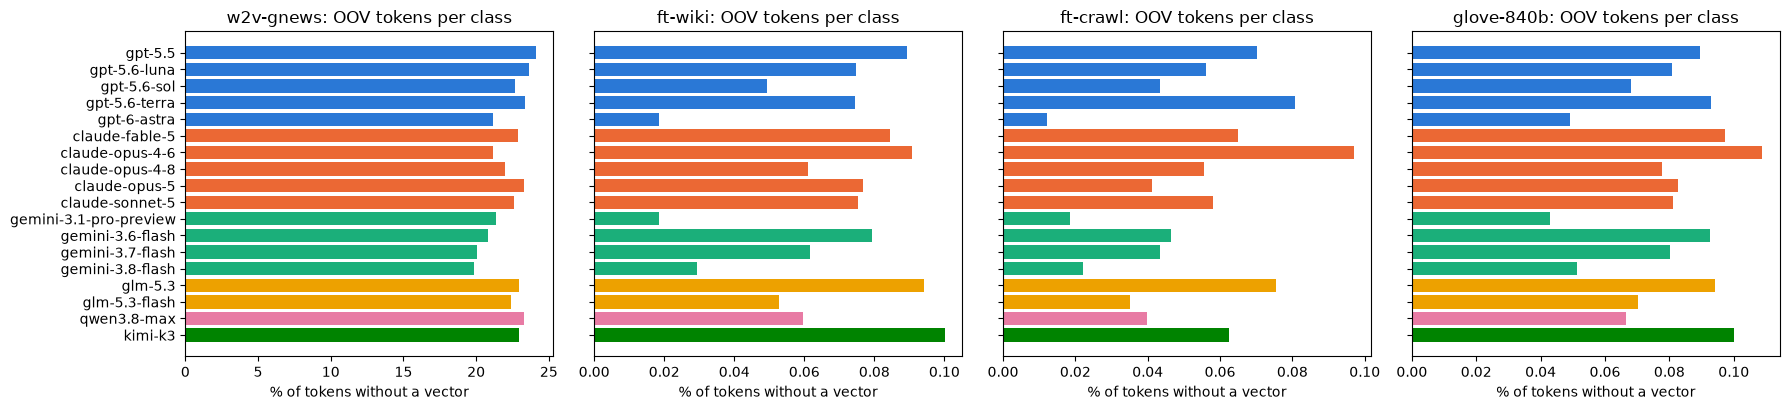

,w2v-gnews,ft-wiki,ft-crawl,glove-840b
y,,,,
gpt-5.5,24.11%,0.09%,0.07%,0.09%
gpt-5.6-luna,23.61%,0.07%,0.06%,0.08%
gpt-5.6-sol,22.68%,0.05%,0.04%,0.07%
gpt-5.6-terra,23.37%,0.07%,0.08%,0.09%
gpt-6-astra,21.16%,0.02%,0.01%,0.05%
claude-fable-5,22.85%,0.08%,0.06%,0.10%
claude-opus-4-6,21.15%,0.09%,0.10%,0.11%
claude-opus-4-8,22.01%,0.06%,0.06%,0.08%
claude-opus-5,23.32%,0.08%,0.04%,0.08%


In [7]:
# Is coverage itself different across authors? (OOV rate per class: a confound if one class loses more tokens)
oov_cls = pd.DataFrame({n: WV.coverage_by_class(TOK[n], texts, models) for n in W}).loc[D.class_order]
fig, axes = plt.subplots(1, len(W), figsize=(4.5 * len(W), 4.2), sharey=True)
cols = [FAMILY_COLOR[family(m)] for m in oov_cls.index]
for ax, n in zip(axes, W):
    ax.barh(oov_cls.index, oov_cls[n] * 100, color=cols)
    ax.set_title(f"{n}: OOV tokens per class")
    ax.set_xlabel("% of tokens without a vector")
axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(FIG_DIR / "oov_by_class.png", dpi=150)
plt.show()
oov_cls.style.format("{:.2%}")

**The cues themselves.** Coverage counts tokens; for us what matters is whether each **cue character** survives as something the model can tell apart from its plain variant. For every occurrence of a cue character in the corpus, we record whether it:
- has its **own vector** (it is a token in the table, or a `mark` token);
- sits **inside a word** that has a vector (e.g. word2vec's `don't`; the cue is part of a distinct type);
- is **folded** away (the word was found only after replacing it with its ASCII twin);
- is **lost** (the token has no vector).

In [8]:
CUE_CHARS = ["—", "–", "-", "’", "'", "“", "”", '"', ";", ":", ",", ".", "(", "…", "?"]


def cue_fate(tok, texts):
    fate = {c: Counter() for c in CUE_CHARS}
    for t in texts:
        for s, k, h in tok.resolve(t):
            for ch in set(s) & set(CUE_CHARS):
                n = s.count(ch)
                if k is None:
                    fate[ch]["lost"] += n
                elif k == ch:
                    fate[ch]["own vector"] += n
                elif ch in k:
                    fate[ch]["inside a word"] += n
                elif h != "mark":
                    fate[ch]["folded"] += n
    return fate


cue_tok = {**{n: TOK[n] for n in W},
           "ft-crawl (curly=mark)": WV.EmbTokenizer(W["ft-crawl"], **{**CONFIG["ft-crawl"], "curly": "mark"}),
           "ft-crawl (tutorial)": TUT["ft-crawl"]}
FATE = {n: cue_fate(t, texts) for n, t in cue_tok.items()}
n_occ = pd.Series({c: sum(t.count(c) for t in texts) for c in CUE_CHARS}, name="occurrences")
fates = pd.DataFrame({n: {c: ", ".join(f"{k} {v}" for k, v in f[c].most_common()) for c in CUE_CHARS}
                      for n, f in FATE.items()})
display(pd.concat([n_occ, fates], axis=1))

,occurrences,w2v-gnews,ft-wiki,ft-crawl,glove-840b,ft-crawl (curly=mark),ft-crawl (tutorial)
—,1476,lost 1476,own vector 1476,own vector 1476,own vector 1476,own vector 1476,own vector 1476
–,6,lost 6,own vector 6,own vector 6,own vector 6,own vector 6,own vector 6
-,1251,"lost 1122, inside a word 2","inside a word 828, own vector 421, lost 2","inside a word 912, own vector 337, lost 2","inside a word 837, own vector 412, lost 2","inside a word 912, own vector 337, lost 2","inside a word 917, lost 334"
’,667,"lost 602, folded 65","folded 639, own vector 28","folded 639, own vector 28","inside a word 639, own vector 28","own vector 667, folded 639",own vector 667
',1174,"lost 956, inside a word 218","inside a word 1121, own vector 50, lost 3","inside a word 1121, own vector 50, lost 3","inside a word 1124, own vector 50","inside a word 1121, own vector 50, lost 3","inside a word 1067, lost 261, own vector 50"
“,89,lost 89,own vector 89,own vector 89,own vector 89,own vector 89,own vector 89
”,89,lost 89,own vector 89,own vector 89,own vector 89,own vector 89,own vector 89
"""",202,lost 202,own vector 202,own vector 202,own vector 202,own vector 202,
;,1100,lost 1100,own vector 1100,own vector 1100,own vector 1100,own vector 1100,own vector 1100
:,1462,lost 1462,own vector 1462,own vector 1462,own vector 1462,own vector 1462,"own vector 1460, lost 2"


**Findings (1.4)**

- **fastText and GloVe cover our texts almost completely.** With our tokeniser, 99.95% of tokens (`ft-crawl`), 99.93% (`ft-wiki`) and 99.92% (`glove-840b`) have a vector, and only 6.0% / 7.9% / 9.0% of texts contain any OOV token. What remains is rare technical vocabulary and proper names (*chemolithotrophic*, *khipukamayuq*, *Göbekli*, *retinohypothalamic*) plus sub- and superscripts (*z²*, *H₂O*). The subword `.bin` models could embed these, but they are about 0.05% of tokens, not worth 7 GB.
- **Each convention from 1.2 is confirmed by coverage.** Switching one option away from ours raises the share of texts with OOV tokens:

  | Change | Texts with OOV |
  |---|---|
  | `clitics=whole` | 51% |
  | `curly=keep` | 25% (every GPT `’s` / `’t`) |
  | `hyphens=keep` | 17% |
  | tutorial pipeline (mostly its `n't`) | 22% |
  | GloVe with the fastText clitic split, or fastText with GloVe's | 11% / 8% (vs 9% / 6%) |

  The token-level differences are small (≤ 0.6 pp) because the affected tokens are rare, so evaluate tokenisers per text, not only per token.
- **word2vec has no vector for 22% of our tokens:**
  - 13.5% punctuation;
  - 8.1% *a/and/of/to*;
  - 0.7% other.

  The tutorial pipeline's higher figure (86%) comes from silently replacing *a* with *A*, *and* with *And*, and so on: its lowercased table keeps the most frequent casing, the same as our `case_backoff=both`. Those are sentence-initial and headline vectors, so we don't count them as coverage. The loss also **depends on the author**: from 19.9% of tokens (Gemini 3.8 Flash) to 24.1% (GPT-5.5).
- **Cues:**
  - fastText gives every cue its own vector: all 1,476 em dashes, every `;` `:` `,` `“` `”` and `"`. Hyphens are kept inside words (*well-known*) or as `-`.
  - The exception is the **curly apostrophe**: with `curly=fold`, 639 of 667 are folded into `'s` / `'t`, which erases the GPT cue. `curly=mark` keeps all 667 as their own `’` token.
  - GloVe keeps every cue too, including the curly clitics natively (`’s`, `n’t`).
  - word2vec loses every punctuation cue.

**Decision (step 1): fastText or GloVe, not word2vec.** word2vec cannot see the stylometric channel at all (punctuation and the four commonest function words), and part 1 showed that this is where the author signal is. fastText and GloVe both pass on coverage and cues; the differences are small, with `ft-crawl` slightly ahead. 2.5 decides downstream, along with the curly-quote option.

## Step 2 · What does the embedding space capture?

### 2.1 Sanity check: general lexical similarity (tutorial exercise)

First we check that the tables loaded correctly and behave as the tutorial describes: cosine similarity, neighbours and analogies. Searches run over the 200k most frequent types, as is standard; rarer rows are mostly noise.

In [9]:
pairs = [("person", "person"), ("person", "human"), ("person", "place"), ("person", "city"), ("person", "car")]
display(pd.DataFrame({n: {f"{a} – {b}": W[n].similarity(a, b) for a, b in pairs} for n in W}))
for n in W:
    print(f"{n:9s} king − man + woman:", [w for w, _ in W[n].analogy("king", "man", "woman", 5)])
    print(f"{'':9s} neighbours of 'essay':", [w for w, _ in W[n].most_similar("essay", 8)])

,w2v-gnews,ft-wiki,ft-crawl,glove-840b
person – person,1.0000,1.0000,1.0000,1.0000
person – human,0.2995,0.4536,0.3624,0.4704
person – place,0.1809,0.4347,0.3282,0.4856
person – city,0.1930,0.4823,0.2050,0.2850
person – car,0.2357,0.4615,0.2513,0.3261


w2v-gnews king − man + woman: ['queen', 'monarch', 'princess', 'crown_prince', 'prince']
          neighbours of 'essay': ['essays', 'Essay', 'poem', 'Essays', 'treatise', 'article', 'essay_contest', 'poems']
ft-wiki   king − man + woman: ['queen', 'monarch', 'kings', 'princess', 'lady']
          neighbours of 'essay': ['essays', 'Essay', 'Essays', 'ESSAY', 'polemic', 'essayist', 'treatise', 'book']
ft-crawl  king − man + woman: ['queen', 'kings', 'monarch', 'Queen', 'King']
          neighbours of 'essay': ['essays', 'Essay', 'Essays', 'dissertation', 'thesis', 'essayists', 'ESSAY', 'Dissertation']
glove-840b king − man + woman: ['queen', 'prince', 'kings', 'princess', 'royal']
          neighbours of 'essay': ['essays', 'Essay', 'dissertation', 'thesis', 'Essays', 'ESSAY', 'writing', 'papersportal.com']


### 2.2 Typography: are our cues distinct points in the space?

Part 1 found that the strongest authorship cues are typographic. For a static model to help, each cue needs a vector **different from its plain twin**. If `’` and `'` sat on top of each other, pooling would merge GPT and Claude texts no matter what the tokeniser keeps. Cosines only mean something relative to a reference, so the last rows give the typical cosine of two random frequent words and of two near-synonyms.

In [10]:
CUE_PAIRS = [("’", "'"), ("“", '"'), ("”", '"'), ("“", "”"), ("—", "-"), ("—", "--"), ("—", "–"), ("—", ","),
             ("—", ":"), (";", ":"), (";", ","), ("…", "..."), ("it's", "it’s"), ("don't", "don’t")]
rng = np.random.default_rng(0)


def random_pair_cos(wv, n=3000, top=20_000):
    i, j = rng.integers(100, top, n), rng.integers(100, top, n)
    U = wv.unit_top
    return float(np.mean(np.sum(U[i] * U[j], 1)))


sim = pd.DataFrame({n: {f"{a}  vs  {b}": (W[n].similarity(a, b) if a in W[n] and b in W[n] else np.nan)
                        for a, b in CUE_PAIRS} for n in W})
sim.loc["reference: random frequent words"] = [random_pair_cos(W[n]) for n in W]
sim.loc["reference: big vs large"] = [W[n].similarity("big", "large") for n in W]
display(sim.style.format("{:.2f}", na_rep="absent"))

for c in ["—", "’", "“", ";", "…"]:
    for n in ["ft-wiki", "ft-crawl", "glove-840b"]:
        print(f"{c} {n:10s}", [w for w, _ in W[n].most_similar(c, 10)])

,w2v-gnews,ft-wiki,ft-crawl,glove-840b
’ vs ',absent,0.48,0.36,0.74
"“ vs """,absent,0.43,0.43,0.69
"” vs """,absent,0.43,0.44,0.68
“ vs ”,absent,0.91,0.92,0.72
— vs -,absent,0.50,0.22,0.35
— vs --,absent,0.60,0.52,0.57
— vs –,absent,0.67,0.61,0.68
"— vs ,",absent,0.45,0.40,0.24
— vs :,absent,0.27,0.31,0.16
; vs :,absent,0.30,0.39,0.34


— ft-wiki    ['–', '--', 'The', 'Preceding', 'by', 'even', 'but', '-', 'one', '--the']
— ft-crawl   ['–', '--', '‒', '─', '―', 'But', '”', 'And', ';', '\x97']
— glove-840b ['–', '”', '--', 'â', '…', '“', 'Perhaps', 'Though', 'Â', '---']
’ ft-wiki    ['s', '‘', '´', '\x92', '′', 'll', '‟', '”', '“', "'s"]
’ ft-crawl   ['‘', 's', 'll', '”', '´', '“', 've', '′', 're', '‟']
’ glove-840b ["'", '‘', '”', '“', '’s', '"', '`', '‟', 'n’t', 'â']
“ ft-wiki    ['”', '„', '‘', '…', '’', '–', 'so-called', 's', '‟', 'ﬁrst']
“ ft-crawl   ['”', '‘', '„', '’', '…', '–', 'said', '″', 'quipped', '\x9d']
“ glove-840b ['‘', '”', '"', '’s', 'titled', '…', 'called', '’', '``', 'n’t']
; ft-wiki    ['Nevertheless', 'while', 'So', 'whereas', 'but', 'although', 'But', 'Likewise', 'if', 'Now']
; ft-crawl   [')', '(', ',', '.--', '--but', '--and', ';', '--that', '--for', '--']
; glove-840b ['--', ',', 'and', '.', ')', '*', 'as', '}', 'etc.', 'which']
… ft-wiki    ['”', '...', '..', '“', '....', '.and', '‘', '.but',

### 2.3 Topic or style: what does a pooled text vector encode?

Embed-and-pool (step 3) represents a text by the mean of its token vectors. Which share of the variation between these mean vectors is **topic** (prompt), and which is **author** (model, family)? We measure η², the between-group share of the total variance (summed over dimensions), for three versions of the pooled vector:
- **all tokens**;
- **content words only** (not in NLTK's stopword list, and containing a letter);
- **function words + punctuation only**, the classic stylometric channel.

η² is not zero for random groups: with G groups and N texts, its expectation is about (G−1)/(N−1). That is 5.5% for 120 prompts, 0.8% for 18 models and 0.2% for 6 families. The table reports these chance levels next to the observed values. The last block repeats the analysis after **prompt-centring** (subtracting each prompt's mean vector, the team's step 7b), which removes the prompt share by construction.

**In plain terms.** Each text becomes one point in 300d space: the average of its word vectors. Colour the points by prompt and ask how tightly each colour clusters; then do the same colouring by author model. η² measures this: the share of the total spread between points explained by the grouping.
- 100% means every text is identical to the others in its group, so the group explains everything.
- 0% means the grouping tells you nothing.

Even random groups get some η² by chance (5.5% for 120 prompts, 0.8% for 18 models), so each number is compared with its chance level.

**What we found, in short:**
- **Topic dominates.** The prompt explains about 65% of the spread, the author only 3–5%. Two texts on the same prompt by different models look far more alike than two texts by the same model on different prompts. It's like listening to a room of conversations: you hear what people are talking about long before you notice their accents.
- **Function words and punctuation are where the author shows.** Averaging only `the`, `of`, `;`, `—` and similar tokens almost halves the topic share (to about 37%) and doubles the author share (to about 8%).
- **Prompt-centring removes topic outright.** Subtracting each prompt's average point removes the topic share by construction, and the author share rises to 12–15%.

**Why it matters for step 3.** A classifier on averaged vectors has to dig a small author signal out from under a large topic signal. That's why prompt-centring gives +12 pp in 2.5, and why pooling function words separately is worth trying.

In [11]:
STOP = set(nltk.corpus.stopwords.words("english")) | {"'s", "'t", "'re", "'ve", "'ll", "'d", "'m", "s", "t"}
is_function = lambda s: s.lower() in STOP or not re.search(r"[^\W\d_]", s)  # stopword, punctuation or number
is_content = lambda s: not is_function(s)
N = len(texts)
chance = {"prompt": (len(set(groups)) - 1) / (N - 1), "model": 17 / (N - 1), "family": 5 / (N - 1)}

POOLED, eta = {}, []
for n in W:
    for channel, keep in [("all tokens", None), ("content words", is_content), ("function words + punct", is_function)]:
        X = WV.pool(TOK[n], texts, keep=keep)
        POOLED[(n, channel)] = X
        Xc = prompt_centre(X, groups)
        eta.append({"table": n, "channel": channel,
                    **{f"η² {g}": WV.variance_explained(X, lab) for g, lab in [("prompt", groups), ("model", models), ("family", fams)]},
                    "η² model, prompt-centred": WV.variance_explained(Xc, models),
                    "η² family, prompt-centred": WV.variance_explained(Xc, fams)})
eta = pd.DataFrame(eta).set_index(["table", "channel"])
print("chance levels:", {k: f"{v:.1%}" for k, v in chance.items()})
eta.style.format("{:.1%}")

chance levels: {'prompt': '5.5%', 'model': '0.8%', 'family': '0.2%'}


### 2.4 Do the models' favourite words form coherent regions?

Part 1 found lexical fingerprints, e.g. Gemini's "profound", "absolute", "microscopic". If one model's favourite words lie in one region of the space, a pooled vector shifts towards that region whenever the model writes, and a linear classifier can use it. For each class (one model vs the 17 others) we find its most distinctive words with the weighted log-odds ratio with an informative Dirichlet prior (Monroe et al. 2008, z-scores). We keep alphabetic words with a total count ≥ 10 that are in the table, and take the top 20. We then compare the **mean pairwise cosine** of these 20 words with 500 random sets of 20 words drawn from the same frequency deciles of our corpus, because frequent words are more similar to one another in these spaces.

**In plain terms.** Two steps:
1. **Find each model's favourite words:** the content words it uses unusually often compared with the other 17 models. For example, Gemini's *profound, abyss, tapestry, primordial*. The log-odds score with a prior stops rare words from winning by luck. Function words are excluded, because otherwise they top every list simply by being frequent.
2. **Check whether those 20 words form a cluster** in the embedding: compute their average pairwise cosine similarity, and compare it with 500 random sets of 20 words of similar frequency. The frequency matching matters because common words are more similar to each other in general. The percentile shows how many random sets the real set beats; 1.00 means it beats all 500.

**Why this tells us something.** If a model's favourite words cluster, every time it uses one the average vector moves a little towards the same region. Those small moves add up, and a linear classifier can pick up the shift. If the favourite words point in random directions, averaging cancels them out.

**What we found, in short:**
- **Coherent (≥ 98th percentile):** all four Gemini models, Opus 4.6, 4.8 and 5, GLM-5.3, and GPT-6 Astra.
- **Not coherent (7th–89th percentile):** most GPT models, Fable, Sonnet 5, GLM-5.3-flash, Qwen and Kimi. Their favourite words are scattered, and some are just prompt-specific noise.
- This fits part 1: Fable and GLM-flash, the hardest classes there, are among the incoherent ones.

**2.3 vs 2.4 in one line each.** 2.3 asks how much author signal the averaged vector holds: a little, mostly topic, though function words and prompt-centring help. 2.4 asks for which models their vocabulary is visible to averaging: for Gemini and most Claude Opus models yes; for most GPT models, Fable and GLM-flash, no.

In [12]:
CHOSEN_FOR_COUNTS = "ft-crawl"  # tokenisation for the counts (fastText conventions); vectors from each table below
word_re = re.compile(r"[A-Za-z][A-Za-z\-]*")
counts = {c: Counter() for c in D.classes}
for t, m in zip(texts, models):
    counts[m].update(s for s in TOK[CHOSEN_FOR_COUNTS].tokens(t) if word_re.fullmatch(s))
total = sum(counts.values(), Counter())


def distinctive(candidates, k=40):
    prior = Counter({w: total[w] for w in candidates})
    out = {}
    for m in D.class_order:
        rest = total.copy()
        rest.subtract(counts[m])
        out[m] = WV.log_odds(counts[m], rest, prior).index[:k].tolist()
    return out


# (i) all words: z-scores reward frequency, so the most distinctive words are function words
top_all = distinctive([w for w, c in total.items() if c >= 10])
# (ii) content words only: the lexical preferences we want to test
pool_words = [w for w, c in total.items() if c >= 10 and w.lower() not in STOP]
top = distinctive(pool_words)
display(pd.DataFrame({m: {"all words": ", ".join(top_all[m][:8]), "content words": ", ".join(top[m][:10])}
                      for m in D.class_order}).T)

,all words,content words
gpt-5.5,"speech, vanishing, and, warm, leans, refusal, ladder, like","speech, vanishing, warm, refusal, leans, like, ladder, begin, maps, less"
gpt-5.6-luna,"may, p, records, while, gather, can, scarlet, making","may, p, records, gather, scarlet, making, gathers, footsteps, therefore, seems"
gpt-5.6-sol,"and, continually, continue, or, assassin, spend, success, smallest","continually, continue, assassin, spend, success, smallest, instruction, change, bell, travel"
gpt-5.6-terra,"T, crowded, may, entered, SCN, repeat, institutions, made","crowded, entered, may, SCN, repeat, institutions, made, swollen, loosened, p"
gpt-6-astra,"familiar, drawing, offer, shelter, helped, joined, can, leave","familiar, drawing, offer, shelter, helped, joined, leave, escape, help, cup"
claude-fable-5,"PA, n, C, she, conversation, suggests, symbols, complete","PA, n, C, conversation, suggests, symbols, complete, harbor, ever, nothing"
claude-opus-4-6,"roughly, most, remarkably, that, deeply, percent, phenomenon, underlying","roughly, remarkably, deeply, percent, phenomenon, underlying, civilization, something, casting, emerges"
claude-opus-4-8,"you, quietly, S, isn, retreat, glimpse, very, we","quietly, glimpse, retreat, lifetime, immensity, author, genuinely, reason, upon, barren"
claude-opus-5,"hundred, the, a, meant, is, woman, That, arriving","hundred, meant, woman, never, arriving, one, ten, million, last, thousand"
claude-sonnet-5,"itself, isn, This, igniting, requires, stability, actually, near","igniting, requires, stability, actually, near, since, alike, ambition, etched, infrastructure"


In [13]:
def coherence(wv, words_by_class, n_words=20, n_rand=500, seed=0):
    rng = np.random.default_rng(seed)
    cand = [w for w in pool_words if w in wv]
    logc = np.log([total[w] for w in cand])
    bins = pd.qcut(logc, 10, labels=False, duplicates="drop")
    by_bin = pd.Series(cand).groupby(bins).apply(list).to_dict()
    bin_of = dict(zip(cand, bins))
    rows = {}
    for m, ws in words_by_class.items():
        ws = [w for w in ws if w in wv][:n_words]
        obs = WV.mean_pairwise_cos(wv, ws)
        null = [WV.mean_pairwise_cos(wv, [by_bin[bin_of[w]][rng.integers(len(by_bin[bin_of[w]]))] for w in ws])
                for _ in range(n_rand)]
        rows[m] = {"mean cos": obs, "random (freq-matched)": np.mean(null), "percentile": (np.array(null) < obs).mean()}
    return pd.DataFrame(rows).T


COH = {n: coherence(W[n], top) for n in W}
coh = pd.concat({n: c["percentile"] for n, c in COH.items()}, axis=1)
coh.loc["mean"] = coh.mean()
print("percentile of each class's top-20 coherence among 500 frequency-matched random sets (0.95+ = coherent):")
display(coh.style.format("{:.2f}").background_gradient(vmin=0, vmax=1, cmap="Blues"))
display(COH["ft-crawl"].round(3))

percentile of each class's top-20 coherence among 500 frequency-matched random sets (0.95+ = coherent):


,w2v-gnews,ft-wiki,ft-crawl,glove-840b
gpt-5.5,0.80,0.76,0.61,0.98
gpt-5.6-luna,0.64,1.00,0.79,0.99
gpt-5.6-sol,0.97,0.99,0.88,1.00
gpt-5.6-terra,0.10,0.35,0.07,0.35
gpt-6-astra,0.95,0.99,0.99,1.00
claude-fable-5,0.59,0.93,0.51,0.92
claude-opus-4-6,0.98,1.00,1.00,0.98
claude-opus-4-8,0.92,0.98,0.98,0.99
claude-opus-5,1.00,1.00,1.00,1.00
claude-sonnet-5,0.88,0.97,0.89,0.99


,mean cos,random (freq-matched),percentile
gpt-5.5,0.130,0.127,0.608
gpt-5.6-luna,0.133,0.126,0.792
gpt-5.6-sol,0.140,0.129,0.884
gpt-5.6-terra,0.111,0.123,0.066
gpt-6-astra,0.150,0.126,0.988
claude-fable-5,0.123,0.123,0.514
claude-opus-4-6,0.162,0.129,1.000
claude-opus-4-8,0.145,0.123,0.982
claude-opus-5,0.179,0.133,1.000
claude-sonnet-5,0.135,0.124,0.894


### 2.5 Task-specific evidence: a linear probe on pooled vectors

The decisive question is whether a model's space separates **our authors**. As a probe we use the cheapest classifier, the shared `logreg` (StandardScaler + multinomial logistic regression, C tuned by nested CV), on the mean-pooled vectors. It runs on the shared 50 folds (10 repeats × 5, grouped by prompt), and comparisons use the team's Bayesian correlated t-test with ROPE = 1 pp. This is not step 3 (no MLP and no tuning of the encoder); it only ranks the embedding choices:
- the three tables, each with our tokeniser;
- **our tokeniser vs the tutorial pipeline** on the same table: does coherent tokenisation matter downstream?
- **curly = fold / mark / keep:** does keeping the curly apostrophe as a token pay off?
- each of these with and without **prompt-centring**.

Part 1 reference points from `shared/results/` sit on the same folds.

In [14]:
FOLDS = H.load_folds(D.train["id"].tolist())
R = {}


def probe_cv(name, X, centred=True):
    R[name] = H.run_cv(X, y, groups, FOLDS, "logreg", name=name)
    if centred:
        R[name + " +centred"] = H.run_cv(prompt_centre(X, groups), y, groups, FOLDS, "logreg", name=name + " +centred")


for n in W:
    probe_cv(f"{n} mean", POOLED[(n, "all tokens")])
for n in ["ft-wiki", "ft-crawl", "glove-840b"]:
    probe_cv(f"{n} mean (tutorial tokeniser)", WV.pool(TUT[n], texts))
for n in ["ft-wiki", "ft-crawl"]:  # GloVe has the curly forms, so the curly option changes nothing there
    for curly in ["mark", "keep"]:
        probe_cv(f"{n} mean (curly={curly})", WV.pool(WV.EmbTokenizer(W[n], **{**CONFIG[n], "curly": curly}), texts))
for n in W:  # which channel carries the author signal?
    for ch in ["content words", "function words + punct"]:
        probe_cv(f"{n} mean ({ch})", POOLED[(n, ch)], centred=False)

w2v-gnews mean               bal.acc 0.2466 ± 0.0240  (50 folds, 4s)
w2v-gnews mean +centred      bal.acc 0.3462 ± 0.0195  (50 folds, 1s)
ft-wiki mean                 bal.acc 0.2913 ± 0.0232  (50 folds, 1s)
ft-wiki mean +centred        bal.acc 0.3941 ± 0.0182  (50 folds, 1s)
ft-crawl mean                bal.acc 0.2773 ± 0.0201  (50 folds, 1s)
ft-crawl mean +centred       bal.acc 0.4007 ± 0.0233  (50 folds, 1s)
glove-840b mean              bal.acc 0.2698 ± 0.0237  (50 folds, 2s)
glove-840b mean +centred     bal.acc 0.3868 ± 0.0223  (50 folds, 1s)
ft-wiki mean (tutorial tokeniser) bal.acc 0.2895 ± 0.0226  (50 folds, 1s)
ft-wiki mean (tutorial tokeniser) +centred bal.acc 0.3960 ± 0.0224  (50 folds, 1s)
ft-crawl mean (tutorial tokeniser) bal.acc 0.2814 ± 0.0212  (50 folds, 1s)
ft-crawl mean (tutorial tokeniser) +centred bal.acc 0.4053 ± 0.0220  (50 folds, 1s)
glove-840b mean (tutorial tokeniser) bal.acc 0.2744 ± 0.0219  (50 folds, 1s)
glove-840b mean (tutorial tokeniser) +centred bal.acc 0

In [15]:
saved = H.load_results()
REF = {k: saved[k] for k in ["length/logreg", "bow-ours4k/logreg", "char-2-4grams/logreg", "lusr/logreg",
                             "lusr-promptcentred/logreg", "qwen3-base-L14-mean-promptcentred/logreg"] if k in saved}
print("reference systems found:", list(REF))
A.results_table({**R, **REF})

reference systems found: ['length/logreg', 'bow-ours4k/logreg', 'char-2-4grams/logreg', 'lusr/logreg', 'lusr-promptcentred/logreg', 'qwen3-base-L14-mean-promptcentred/logreg']


,folds,minutes,balanced_accuracy,accuracy,macro_f1
system,,,,,
qwen3-base-L14-mean-promptcentred/logreg,50,0.1,0.4873 ± 0.0226,0.4875 ± 0.0226,0.4806 ± 0.0204
lusr-promptcentred/logreg,50,0.2,0.4405 ± 0.0244,0.4406 ± 0.0244,0.4342 ± 0.0241
ft-crawl mean (curly=mark) +centred,50,0.0,0.4060 ± 0.0245,0.4061 ± 0.0245,0.3949 ± 0.0263
ft-crawl mean (curly=keep) +centred,50,0.0,0.4056 ± 0.0248,0.4057 ± 0.0248,0.3945 ± 0.0268
ft-crawl mean (tutorial tokeniser) +centred,50,0.0,0.4053 ± 0.0222,0.4054 ± 0.0222,0.3933 ± 0.0251
ft-crawl mean +centred,50,0.0,0.4007 ± 0.0235,0.4008 ± 0.0235,0.3885 ± 0.0256
ft-wiki mean (curly=mark) +centred,50,0.0,0.3994 ± 0.0177,0.3995 ± 0.0177,0.3864 ± 0.0191
ft-wiki mean (tutorial tokeniser) +centred,50,0.0,0.3960 ± 0.0226,0.3962 ± 0.0226,0.3849 ± 0.0247
ft-wiki mean (curly=keep) +centred,50,0.0,0.3955 ± 0.0180,0.3956 ± 0.0180,0.3822 ± 0.0183


In [16]:
best = "ft-crawl mean"
pairs = [  # (A, B): the table reports B − A
    ("w2v-gnews mean", "ft-crawl mean"), ("w2v-gnews mean +centred", "ft-crawl mean +centred"),
    ("ft-wiki mean", "ft-crawl mean"), ("ft-wiki mean +centred", "ft-crawl mean +centred"),
    ("ft-crawl mean", "ft-crawl mean (curly=mark)"), ("ft-crawl mean (curly=keep)", "ft-crawl mean (curly=mark)"),
    ("ft-crawl mean +centred", "ft-crawl mean (curly=mark) +centred"),
    ("ft-crawl mean (tutorial tokeniser)", "ft-crawl mean (curly=mark)"),
    ("ft-wiki mean (tutorial tokeniser)", "ft-wiki mean (curly=mark)"),
    ("ft-crawl mean (content words)", "ft-crawl mean (function words + punct)"),
    ("ft-crawl mean", "ft-crawl mean +centred"),
    ("glove-840b mean", "ft-crawl mean (curly=mark)"), ("glove-840b mean +centred", "ft-crawl mean (curly=mark) +centred"),
    ("w2v-gnews mean", "glove-840b mean"), ("glove-840b mean (tutorial tokeniser)", "glove-840b mean"),
]
pairs += [(a, b) for a, b in [("char-2-4grams/logreg", "ft-crawl mean (curly=mark)"),
                              ("bow-ours4k/logreg", "ft-crawl mean (curly=mark)"),
                              ("lusr/logreg", "ft-crawl mean (curly=mark)"),
                              ("lusr-promptcentred/logreg", "ft-crawl mean (curly=mark) +centred")] if a in REF]
table, cmps = A.comparison_table({**R, **REF}, pairs=pairs)
table

,A,B,folds,mean B−A,P(A>B),P(ROPE),P(B>A)
0,w2v-gnews mean,ft-crawl mean,50,0.0307,0.0032,0.0736,0.9232
1,w2v-gnews mean +centred,ft-crawl mean +centred,50,0.0545,0.0000,0.0003,0.9997
2,ft-wiki mean,ft-crawl mean,50,-0.0140,0.6141,0.3437,0.0422
3,ft-wiki mean +centred,ft-crawl mean +centred,50,0.0066,0.0452,0.5935,0.3613
4,ft-crawl mean,ft-crawl mean (curly=mark),50,0.0080,0.0039,0.6160,0.3801
5,ft-crawl mean (curly=keep),ft-crawl mean (curly=mark),50,0.0007,0.0798,0.8101,0.1102
6,ft-crawl mean +centred,ft-crawl mean (curly=mark) +centred,50,0.0053,0.0043,0.7944,0.2012
7,ft-crawl mean (tutorial tokeniser),ft-crawl mean (curly=mark),50,0.0039,0.0953,0.6210,0.2837
8,ft-wiki mean (tutorial tokeniser),ft-wiki mean (curly=mark),50,0.0064,0.0533,0.5852,0.3614
9,ft-crawl mean (content words),ft-crawl mean (function words + punct),50,0.0496,0.0000,0.0024,0.9976


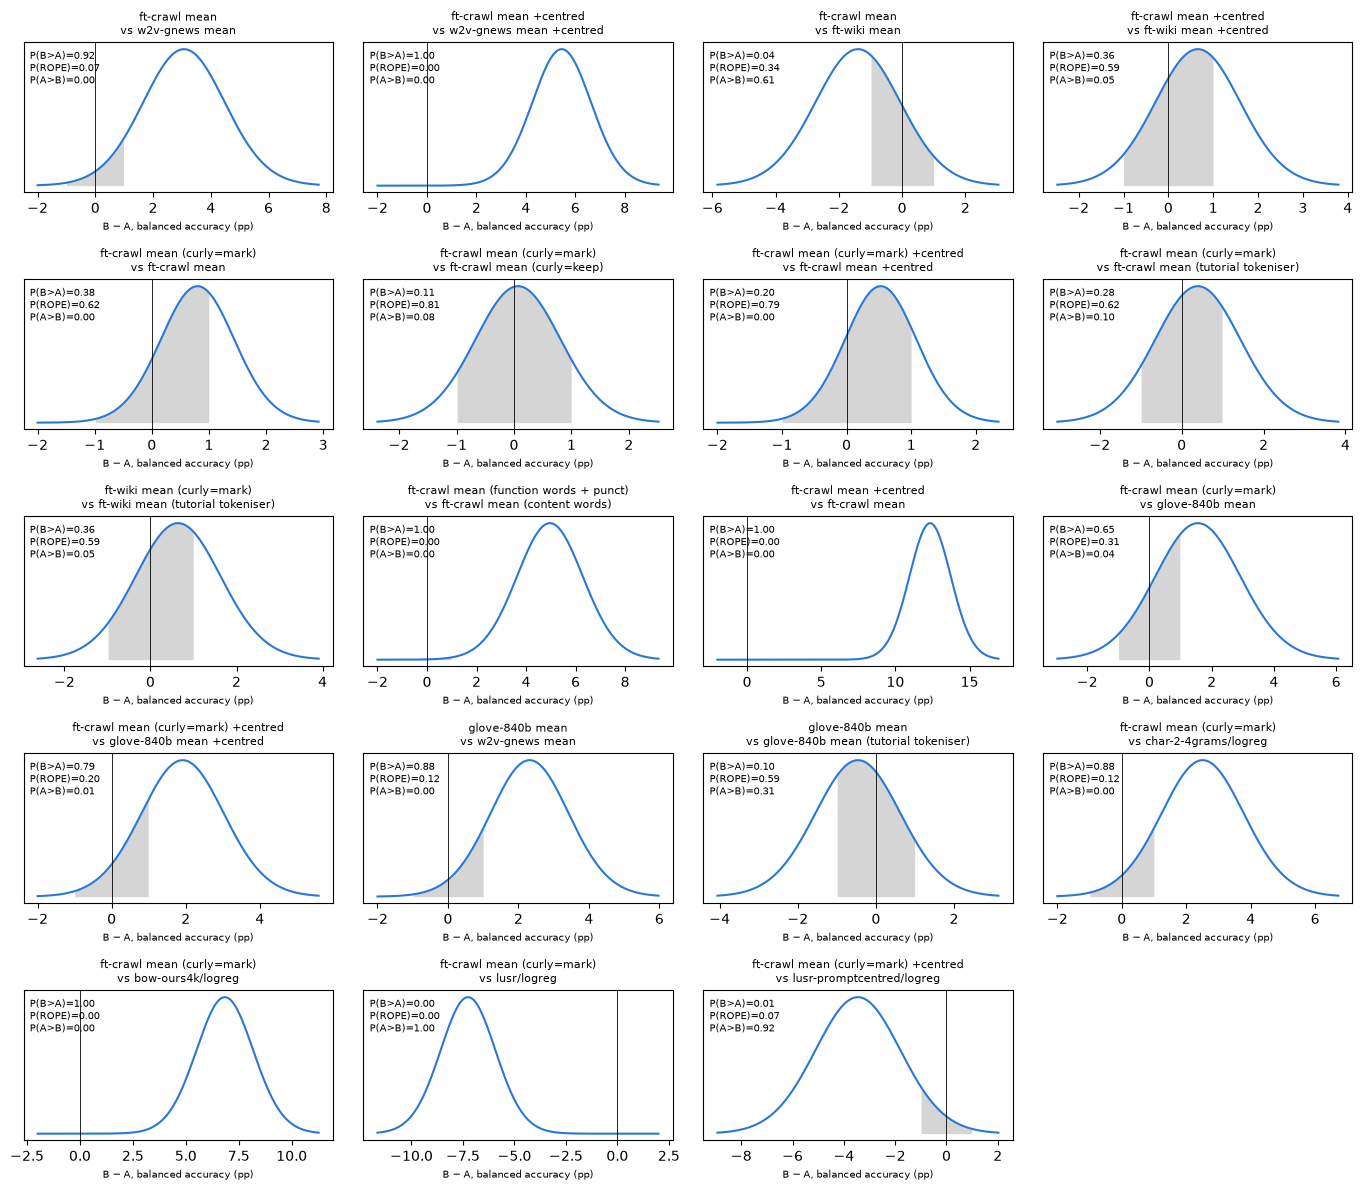

In [17]:
fig = A.plot_posteriors(cmps, ncols=4, path=FIG_DIR / "probe_posteriors.png")

In [18]:
# Family vs within-family accuracy of the probe (out-of-fold predictions, first repeat)
fam_rows = {k: A.family_errors(y, R[k]["oof_pred"], D) for k in ["w2v-gnews mean", "ft-wiki mean", "glove-840b mean",
                                                                   "ft-crawl mean (curly=mark)", "ft-crawl mean (curly=mark) +centred"]}
pd.DataFrame(fam_rows).T

,model_accuracy,family_accuracy,errors,within_family_share_of_errors,within_family_share_if_uniform
w2v-gnews mean,0.2478,0.5609,1624.0,0.4163,0.1765
ft-wiki mean,0.2876,0.6211,1538.0,0.4681,0.1765
glove-840b mean,0.2788,0.6086,1557.0,0.4573,0.1765
ft-crawl mean (curly=mark),0.2955,0.6225,1521.0,0.4642,0.1765
ft-crawl mean (curly=mark) +centred,0.4071,0.6994,1280.0,0.4930,0.1765


**Findings (step 2)**

- **2.1 Sanity.**
  - All three tables load correctly: *king − man + woman* gives *queen*, and the neighbours of *essay* are sensible.
  - Cosine scales differ between tables. Two random frequent words have cosine 0.06 in word2vec, 0.25 in `ft-wiki`, 0.10 in `ft-crawl` and 0.07 in GloVe, so compare a cosine with its table's reference row, not across tables.
- **2.2 The cues are separate points in fastText.**
  - In `ft-crawl`, `’` vs `'` is 0.36 and `—` vs `-` is 0.22: above two random words (0.10) but far below near-synonyms (*big*/*large* 0.69). The space does **not** conflate curly with straight, or em dash with hyphen, so pooling keeps the cue. `“` vs `”` (0.92) are near-identical, which is harmless because they come in pairs.
  - **GloVe has the curly tokens but places them almost on the straight ones:** `’` vs `'` is 0.74 and `“` vs `"` 0.69, both above *big*/*large* (0.66). Pooling therefore largely merges in the space what the tokeniser kept apart. fastText keeps them apart (0.36), which is one plausible reason it wins in 2.5. GloVe's neighbours of `—` also include mojibake (`â`, `Â`), encoding noise in its 2014 crawl.
  - The neighbourhoods encode **function**:
    - `’` sits with `‘`, `s`, `ll`, `ve` (clitic marker);
    - `—` sits with other dashes and with `;`, *But*, *And* (clause joiner), which is how Claude uses it;
    - `…` sits with emojis in Common Crawl, a web/informal register.
- **2.3 A pooled vector is mostly topic.**
  - The prompt explains 63–68% of the variance of the all-token mean vector (chance 5.5%); the model only 3–5% (chance 0.8%).
  - Pooling **only function words and punctuation** almost halves the prompt share (37–38%) and roughly doubles the model share (7.6–8.1% for fastText and GloVe). In word2vec this channel stays weak (3.3%) because its punctuation and *a/and/of/to* are missing.
  - Prompt-centring lifts the model share to 12–15%.
- **2.4 Lexical fingerprints: some authors have a semantic register, others don't.**
  - Ranking by z-score over **all** words puts function words first (*a*, *and*, *of*, *an*, *we*, *you*). These are the most reliable differences between authors, consistent with 2.3.
  - Among **content** words, part 1's fingerprints reappear: Gemini 3.1 Pro's *profound, ultimate, absolute, microscopic*; Gemini Flash's *expanse, abyss, tapestry, primordial*; Opus 4.6's *roughly, remarkably, deeply*.
  - For all four Gemini models, Opus 4.6/4.8/5 and GLM-5.3, these words are **more similar to each other than frequency-matched random words** (≥ 98th percentile in `ft-crawl`). A pooled vector moves towards a region when they write, which a linear model can use.
  - For most GPT models (all but GPT-6 Astra), Claude Fable 5, Sonnet 5, GLM-5.3-flash, Qwen and Kimi, the favourite words are less coherent (7th–89th percentile), and partly prompt-specific noise (*PA*, *SCN*, *assassin*). The space offers less for these classes, and Fable and GLM-flash are exactly the hard classes from part 1.
- **2.5 Task-specific evidence** (logistic-regression probe, 50 folds, ROPE 1 pp; balanced accuracy):
  - **fastText beats word2vec:** +3.1 pp raw (P = 0.92) and +5.5 pp after prompt-centring (P ≈ 1.00).
  - **fastText beats GloVe, narrowly:** `ft-crawl` (`mark`) is +1.6 pp over GloVe raw (P = 0.66, P(ROPE) = 0.31) and +1.9 pp prompt-centred (P = 0.79). GloVe in turn beats word2vec (+2.3 pp, P = 0.88). GloVe's pooled vectors have the *most* author variance by η² (2.3) but are less linearly usable, consistent with its curly/straight conflation (2.2). GloVe is a reasonable second choice and the natural "other algorithm" for step 3.
  - **`ft-crawl` ≈ `ft-wiki`:**
    - raw: wiki +1.4 pp, P(wiki better) = 0.61;
    - centred: crawl +0.7 pp, P(ROPE) = 0.59, P(wiki better) = 0.05.

    Practically equivalent. We take `ft-crawl` for its slightly better coverage, its larger and closer web corpus, and its best centred score.
  - **The author signal is in function words and punctuation:** that channel alone (27.1%) is +5.0 pp over content words alone (P = 0.998) and almost equal to all tokens.
  - **Curly quotes: don't fold.** `curly=mark` beats `fold` (+0.8 pp, P(fold better) = 0.004; centred +0.5 pp, P(fold better) = 0.004) and ties with `keep`. Folding is the only option that erases the cue, so it is the only one that hurts. **Final setting: `curly=mark`** (`WV.TOKENIZER_CONFIG`).
  - **Our tokeniser vs the tutorial pipeline:** within the ROPE for mean pooling (+0.4 to +0.6 pp, P(ROPE) ≈ 0.6). The coverage gains in 1.4 concern rare tokens, which barely move a mean of about 134 vectors. The tutorial tokeniser also keeps `’` as a separate token, like `mark`. We keep ours because it matches each model's definition of a token, which matters more for step 4: sequence models see each `<unk>`, and the tutorial pipeline maps every `n't` to `<unk>` and lowercases.
  - **Against part 1:**

    | System (part 1) | ft-crawl (`mark`) | P |
    |---|---|---|
    | bag-of-words on our BPE-4k, 21.7% | 28.5%, +6.8 pp | ≈ 1.00 |
    | character 2–4-grams, 26.0% | +2.5 pp | 0.88 |
    | LUSR, 35.8% | −7.3 pp | |
    | LUSR prompt-centred, 44.1% | 40.6%, −3.5 pp | P(LUSR better) = 0.92 |

    A frozen 300d static space, averaged, gets about 90% of the way to a style-trained transformer encoder.
  - **Families:** 62% (raw) and 70% (centred) family accuracy, with 46–49% of errors staying inside the true family (18% if errors were uniform). This is the same structure as in part 1: families are separable, the models within a family much less so.

### 2.6 Limitations, and which ones hurt this task

Short demonstrations of the limits we discuss below.

In [19]:
# (a) Static: one vector per type, whatever the context. Neighbours mix senses and functions.
for w in ["like", "just", "light", "kind"]:
    print(f"{w:6s}", [x for x, _ in W["ft-crawl"].most_similar(w, 10)])

# (b) Pre-LLM corpora: "LLM-isms" get ordinary meaning-based neighbours; nothing encodes that LLMs overuse them.
print()
for w in ["delve", "tapestry", "testament", "profound"]:
    print(f"{w:10s} rank {W['ft-crawl'].rank(w):>7,}", [x for x, _ in W["ft-crawl"].most_similar(w, 8)])

# (c) Pooling dilutes rare cues: weight of the em-dash tokens in the mean vector of texts that use one
share = []
for t in texts:
    r = TOK["ft-crawl"].resolve(t)
    k = sum(s == "—" for s, _, _ in r)
    if k:
        share.append(k / len(r))
print(f"\n(c) texts with an em dash: {len(share)}; the dashes are {np.median(share):.1%} of the tokens (median) "
      f"→ about that share of the mean vector")

# (d) word2vec drops exactly the stylometric channel
lost = Counter()
for t in texts:
    for s, k, _ in TOK["w2v-gnews"].resolve(t):
        if k is None:
            lost["punctuation" if not re.search(r"\w", s) else ("a/and/of/to" if s.lower() in {"a", "and", "of", "to"} else "other")] += 1
n_tok = sum(len(TOK["w2v-gnews"].resolve(t)) for t in texts)
print("(d) word2vec, share of all tokens without a vector:", {k: f"{v / n_tok:.1%}" for k, v in lost.items()})

like   ['lke', 'Like', 'liek', 'lik', 'think', 'LIke', 'liken', 'akin', 'want', 'just']
just   ['jsut', 'simply', 'really', 'jut', 'Just', 'only', 'juts', 'actually', 'it', 'not']
light  ['Light', 'light.', 'light-', 'light.The', 'illumination', 'darkness', 'dark', 'light.I', 'lights', 'illuminated']
kind   ['sort', 'Kind', 'kind.', 'kindest', 'considerate', 'warm-hearted', 'kindhearted', 'caring', 'thing', 'kind-hearted']

delve      rank  45,769 ['delving', 'delved', 'delves', 'explore', 'dig', 'dissect', 'unearth', 'deeper']
tapestry   rank  25,850 ['tapestries', 'woven', 'Tapestry', 'weaving', 'Tapestries', 'weave', 'weavings', 'wove']
testament  rank  21,048 ['testaments', 'attests', 'indisputable', 'dedication', 'attest', 'remarkable', 'codicil', 'attesting']
profound   rank   8,502 ['Profound', 'far-reaching', 'profoundly', 'life-altering', 'poignant', 'profundity', 'profoundest', 'heartfelt']

(c) texts with an em dash: 852; the dashes are 1.2% of the tokens (median) → about th

**Limitations of static word embeddings, ranked by how much they hurt this task**

1. **They encode meaning, and our label is not meaning (2.3).** Distributional training puts words that occur in similar contexts close together, so a pooled vector mostly says *what the text is about*. Here that is the prompt (63–69% of the variance), which carries no label information. Prompt-centring removes it, but only because our dataset has the one-answer-per-model-per-prompt design.
2. **Pooling dilutes the rare cues.** The em dashes are 1.2% of the tokens of a text that uses them (median), so 1.2% of the mean vector. A single spaced em dash or curly apostrophe barely moves it. Weighted or max pooling (step 3), or a sequence model (step 4), can give single tokens more weight.
3. **What the tokeniser throws away cannot come back.** No token stands for whitespace, so the **spaced em dash (" — ")**, which part 1 found only Opus 4.6 and Opus 5 write, looks identical to an unspaced one. Possible fixes are a marker token (e.g. `␣—`) with a learned vector, or hand-made typography counts concatenated to the pooled vector.
4. **Static = one vector per type, whatever the context.** *like* (preposition, verb, discourse marker) and *just* each get one vector, whose neighbours here are misspellings and synonyms of one sense. An em dash that opens an aside and one that replaces a colon are the same vector. Contextual models (LUSR, Qwen3) do not have this limit, which is part of their lead in 2.5.
5. **The training corpora predate LLMs** (2013–2017 news, Wikipedia, web). *delve*, *tapestry* and *testament* get ordinary meaning neighbours (*explore, dig*; *woven, weaving*); nothing in the space reflects that LLMs overuse them. Frequency-of-use information has to come from our own training data.
6. **Order-blind once pooled:** *dog bites man* and *man bites dog* give the same vector (tutorial). For style this matters less than for meaning, but sentence rhythm and clause order are lost.
7. **OOV without subwords:** with the `.vec` files, about 6% of texts contain at least one word with no vector, all rare technical terms. Mild for us; the fastText `.bin` files would fix it. GloVe and word2vec have no subword mechanism at all.
8. **Model-specific to GloVe 840B:** typographic characters are rare in its corpus, its curly and straight quotes are near-synonyms in the space (2.2), and the 2014 crawl contains encoding noise (mojibake neighbours).
9. **Model-specific to word2vec:** no punctuation and no *a/and/of/to*, 22% of our tokens, which is exactly the stylometric channel. This, more than the 3–5 pp gap, is why we rule word2vec out.
10. **Social biases** (Bolukbasi et al. 2016): the analogies reproduce stereotypes. This is real but has no direct effect on authorship classification.

**Most troubling for us:** 1–3. The model's notion of similarity is semantic while our label is stylistic, and the stylistic cues are rare tokens that pooling averages away or that the tokeniser cannot see. The natural responses are prompt-centring, a function-word + punctuation channel, cue markers, and sequence encoders (steps 3–4).

## Hand-off to steps 3–4

`python -m part2.prepare_embeddings` (add `--all` for every table, `--probe` to re-run 2.5) downloads the files, builds and verifies the small per-table subsets, and checks them against the fingerprints in `shared/embeddings_manifest.json`. The subset holds only the types our texts use (train.csv + Kaggle test.csv; no labels used), about 20 MB instead of 2.4 GB, and gives exactly the same token ids as the full table. `SubsetEmbeddings` is a drop-in for `clslib.PretrainedEmbeddings`, so `part2.experiment.train` works unchanged.

```python
from part2 import wordvecs as WV
tok, emb = WV.load_subset(WV.CHOSEN)                 # "ft-crawl"; or "glove-840b", "ft-wiki", "w2v-gnews"
metrics, best_epoch = part2.experiment.train(train_pairs, val_pairs, tok, emb, num_classes=18,
                                             enc_type="embed-and-pool", enc_kwargs={"freeze_embeddings": True}, ...)
emb_small  = emb.pca(50)                             # embedding-size axis (step 3), same ids
emb_random = emb.random_like(seed=0)                 # pretrained vs random init (step 4), same ids
```

In [20]:
import torch

from part2 import clslib

import json

from part2 import prepare_embeddings as PE

CHOSEN = WV.CHOSEN
assert WV.TOKENIZER_CONFIG[CHOSEN] == {**CONFIG[CHOSEN], "curly": "mark"}  # final setting = step-1 config + 2.5's choice
manifest = json.loads(PE.MANIFEST.read_text())
entry = PE.build(CHOSEN, PE.all_texts(), manifest, update=False)  # builds + verifies; stops if it differs from the manifest
print(f"fingerprint matches the manifest: {entry['subset_fingerprint'] == manifest[CHOSEN]['subset_fingerprint']}")

tok, emb = WV.load_subset(CHOSEN)
probe_here = H.fold_scores(R["ft-crawl mean (curly=mark)"]).mean()
print(f"probe in this notebook {probe_here:.4f} vs manifest {manifest[CHOSEN]['probe_bal_acc-raw']:.4f}")
assert abs(probe_here - manifest[CHOSEN]["probe_bal_acc-raw"]) < 1e-4

[ft-crawl] hashing crawl-300d-2M.vec.zip
WordVectors('ft-crawl', 1,999,995 types x 300d)  loaded in 0s
[ft-crawl] OK: 19,517 types x 300d -> cache/wordvecs/subset-ft-crawl.npz  (fingerprint c81b13dd28ef)
fingerprint matches the manifest: True
probe in this notebook 0.2853 vs manifest 0.2853
